# A/B-тест формы оплаты ЖКХ

**Вопрос:** стоит ли масштабировать новую форму с упрощённым вводом реквизитов?

- Вариант A — текущая форма; вариант B — новая форма.
- Период: 1–30 апреля 2024 года.
- **Единица рандомизации — пользователь**, поэтому основная гипотеза проверяется на уровне уникальных пользователей, а не платежей.

**Результат:** новая форма B повышает пользовательскую конверсию с 65,73% до 80,40% (+14,67 п.п.; p ≈ 1,53 × 10⁻¹⁰). Рекомендовано поэтапное масштабирование с контролем защитных метрик.

Исходный Excel не опубликован. Чтобы повторить расчёты, поместите файл в `data/data.xlsx` (локальный Jupyter) или загрузите при запросе в Google Colab. В этом ноутбуке сохранены результаты выполнения, поэтому ключевые таблицы и графики видны без запуска кода.

## 1. Загрузка и первичный EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

filename = Path('data/data.xlsx')
if not filename.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        filename = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError('Поместите исходный Excel в data/data.xlsx')

users = pd.read_excel(filename, sheet_name='Пользователи')
payments = pd.read_excel(filename, sheet_name='Платежи')
print('Пользователи:', users.shape, 'Платежи:', payments.shape)
# Не выводим строки исходных данных: в публичном ноутбуке оставляем только агрегаты.

Пользователи: (1504, 5) Платежи: (2661, 7)


In [2]:
print('Пропуски — пользователи:')
display(users.isna().sum().to_frame('missing'))
print('Пропуски — платежи:')
display(payments.isna().sum().to_frame('missing'))
print('Дубликаты user_id:', users.duplicated('user_id').sum())
print('Дубликаты payment_id:', payments.duplicated('payment_id').sum())
print('Группы пользователей:')
display(users['group'].value_counts(dropna=False))

Пропуски — пользователи:


,missing
user_id,0
group,1
age,0
city,1
device_type,0


Пропуски — платежи:


,missing
payment_id,0
user_id,1
group,0
step1_opened,0
step2_entered,405
step3_confirmed,942
step4_success,1139


Дубликаты user_id: 0
Дубликаты payment_id: 0
Группы пользователей:


group
A      752
B      751
NaN      1
Name: count, dtype: int64

### 1.1. Правила очистки

- Нельзя восстанавливать неизвестную A/B-группу предположениями.
- При противоречии группы в таблицах пользователь исключается из основного сравнения (в рамках этого кейса — один пользователь).
- Попытка с пустым идентификатором пользователя не пригодна для пользовательской конверсии.
- Ошибочный возраст превращается в настоящий пропуск (`NaN`), но пользователь остаётся в основной выборке.
- Пропуск города допустим для общей метрики; для сегментного анализа хранится как `NaN`.
- Пустые даты следующих этапов — нормальный способ кодировать незавершённую воронку.

In [3]:
for table in (users, payments):
    table['group'] = table['group'].astype('string').str.strip()

check = payments.merge(users[['user_id', 'group']], on='user_id', how='left',
                       suffixes=('_payment', '_user'), validate='many_to_one')
conflicts = check.loc[
    check['group_user'].isin(['A','B']) &
    check['group_payment'].isin(['A','B']) &
    (check['group_user'] != check['group_payment']), 'user_id'
].dropna().unique()
mixed = payments.groupby('user_id')['group'].nunique(dropna=True)
ambiguous = set(conflicts) | set(mixed[mixed > 1].index)

users_clean = users.loc[
    users['group'].isin(['A','B']) & ~users['user_id'].isin(ambiguous)
].copy()
payments_clean = payments[payments['user_id'].isin(users_clean['user_id'])].copy()
users_clean['age'] = pd.to_numeric(users_clean['age'], errors='coerce')
users_clean.loc[~users_clean['age'].between(18,100), 'age'] = np.nan
users_clean['city'] = users_clean['city'].replace(['NaN','nan','Неизвестен',''], np.nan)

assert users_clean['user_id'].is_unique
assert payments_clean['payment_id'].is_unique
assert payments_clean.merge(users_clean[['user_id','group']], on='user_id',
    suffixes=('_payment','_user'))    .eval('group_payment == group_user').all()

print('Число пользователей с противоречивой A/B-группой:', len(ambiguous))
print('Осталось:', len(users_clean), 'пользователей;', len(payments_clean), 'попыток')
display(users_clean['group'].value_counts())

Число пользователей с противоречивой A/B-группой: 1
Осталось: 1502 пользователей; 2658 попыток


/tmp/ipykernel_2884/264271287.py:25: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  suffixes=('_payment','_user'))    .eval('group_payment == group_user').all()


group
A    751
B    751
Name: count, dtype: Int64

In [4]:
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
for column in steps:
    payments_clean[column] = pd.to_datetime(payments_clean[column], errors='coerce')

out_of_order = pd.Series(False, index=payments_clean.index)
for prev, nxt in zip(steps[:-1], steps[1:]):
    out_of_order |= payments_clean[nxt].notna() & (
        payments_clean[prev].isna() | (payments_clean[nxt] < payments_clean[prev])
    )
outside = ~payments_clean['step1_opened'].between(
    pd.Timestamp('2024-04-01'), pd.Timestamp('2024-05-01'), inclusive='left'
)
print('Нарушений этапов:', out_of_order.sum(), 'Попыток вне периода:', outside.sum())
assert not out_of_order.any() and not outside.any()

Нарушений этапов: 0 Попыток вне периода: 0


## 2. Воронки и главная метрика

In [5]:
attempt_counts = payments_clean.groupby('group')[steps].count()
attempt_conversion = attempt_counts['step4_success'] / attempt_counts['step1_opened']
print('Воронка попыток:')
display(attempt_counts.T)
print('Конверсия попыток, %:')
display((attempt_conversion * 100).round(2))

Воронка попыток:


group,A,B
step1_opened,1307,1351
step2_entered,1061,1194
step3_confirmed,758,960
step4_success,651,870


Конверсия попыток, %:


group
A    49.81
B    64.40
dtype: float64

In [6]:
user_funnel = payments_clean.groupby(['group','user_id'])[steps].agg(
    lambda x: x.notna().any()
).reset_index()
user_counts = user_funnel.groupby('group')[steps].sum().astype(int)
user_conversion = user_counts['step4_success'] / user_counts['step1_opened']
print('Воронка уникальных пользователей:')
display(user_counts.T)
print('Пользовательская конверсия, %:')
display((user_conversion * 100).round(2))
print('Абсолютный эффект, п.п.:', round((user_conversion['B']-user_conversion['A'])*100,2))
print('Относительный uplift, %:', round((user_conversion['B']/user_conversion['A']-1)*100,2))

Воронка уникальных пользователей:


group,A,B
step1_opened,750,750
step2_entered,671,707
step3_confirmed,548,644
step4_success,493,603


Пользовательская конверсия, %:


group
A    65.73
B    80.40
dtype: float64

Абсолютный эффект, п.п.: 14.67
Относительный uplift, %: 22.31


## 3. Статистическая проверка

**H₀:** конверсия одинаковая в A и B. **H₁:** конверсия различается.

Двусторонний Z-тест долей на **уникальных пользователях**, α = 0,05. 95%-й ДИ абсолютной разницы — методом Newcombe.

In [7]:
success_b = int(user_counts.loc['B','step4_success'])
success_a = int(user_counts.loc['A','step4_success'])
n_b = int(user_counts.loc['B','step1_opened'])
n_a = int(user_counts.loc['A','step1_opened'])
z, pvalue = proportions_ztest([success_b,success_a], [n_b,n_a], alternative='two-sided')
lo,hi = confint_proportions_2indep(success_b,n_b,success_a,n_a,compare='diff',method='newcomb')
print(f'Z = {z:.3f}, p = {pvalue:.3e}, 95% ДИ: [{lo*100:.2f}; {hi*100:.2f}] п.п.')

Z = 6.402, p = 1.530e-10, 95% ДИ: [10.21; 19.05] п.п.


### 3.1. График пользовательской воронки

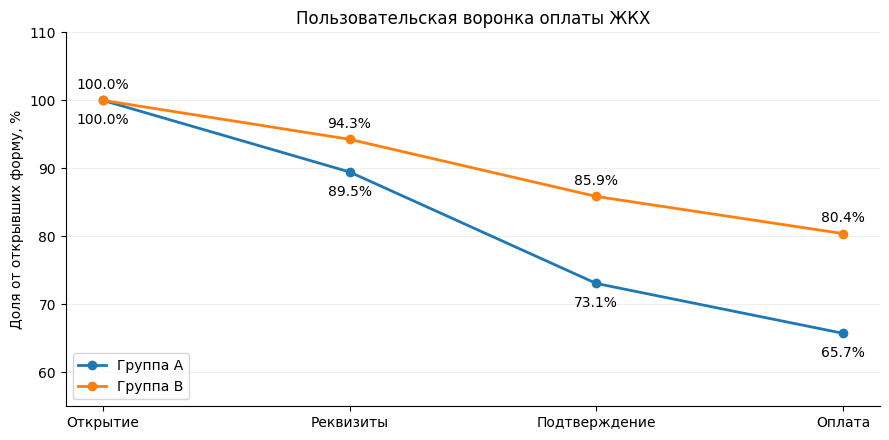

In [8]:
stages = ['Открытие','Реквизиты','Подтверждение','Оплата']
fig,ax = plt.subplots(figsize=(9,4.5))
for g in ['A','B']:
    vals = user_counts.loc[g, steps].to_numpy(dtype=float) / user_counts.loc[g,'step1_opened'] * 100
    ax.plot(stages, vals, marker='o', linewidth=2, label=f'Группа {g}')
    for i,v in enumerate(vals):
        ax.annotate(f'{v:.1f}%', (i,v), xytext=(0,8 if g=='B' else -17), textcoords='offset points', ha='center')
ax.set_ylim(55,110)
ax.set_ylabel('Доля от открывших форму, %')
ax.set_title('Пользовательская воронка оплаты ЖКХ')
ax.legend(loc='lower left'); ax.grid(axis='y', alpha=.20)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

## 4. Исследовательские проверки

Эти расчёты дополняют основной вывод, но **не** доказывают, что эффект вызван ускорением или сокращением ошибок автозаполнения.

In [9]:
# Конверсия между последовательными этапами
step_conversion = user_counts[steps[1:]].to_numpy(dtype=float) / user_counts[steps[:-1]].to_numpy(dtype=float) * 100
step_table = pd.DataFrame(step_conversion.T, index=['1→2','2→3','3→4'], columns=user_counts.index)
step_table['B−A, п.п.'] = step_table['B'] - step_table['A']
display(step_table.round(2))

group,A,B,"B−A, п.п."
1→2,89.47,94.27,4.80
2→3,81.67,91.09,9.42
3→4,89.96,93.63,3.67


In [10]:
# Для времени: медиана по попыткам каждого пользователя, затем по пользователям
rows=[]
for label,a,b in zip(['1→2','2→3','3→4'],steps[:-1],steps[1:]):
    tmp=payments_clean.dropna(subset=[a,b]).copy()
    tmp['minutes']=(tmp[b]-tmp[a]).dt.total_seconds()/60
    tmp=tmp[tmp['minutes']>=0]
    pu=tmp.groupby(['group','user_id'])['minutes'].median().reset_index()
    for g in ['A','B']:
        v=pu.loc[pu['group']==g,'minutes']
        rows.append({'transition':label,'group':g,'users':len(v),'median_min':v.median(),'mean_min':v.mean()})
time_results=pd.DataFrame(rows)
display(time_results.round(2))

,transition,group,users,median_min,mean_min
0,1→2,A,671,2.0,2.27
1,1→2,B,707,2.0,2.37
2,2→3,A,548,4.5,4.57
3,2→3,B,644,4.5,4.47
4,3→4,A,493,5.5,5.51
5,3→4,B,603,5.5,5.47


In [11]:
# Сегментные срезы (описательно, без заявлений о неоднородности эффекта)
segment = users_clean[['user_id','group','device_type','city','age']].merge(
    user_funnel[['user_id','step1_opened','step4_success']], on='user_id', validate='one_to_one'
)
segment=segment[segment['step1_opened']==True].copy()
segment['age_group']=pd.cut(segment['age'],bins=[18,25,35,45,101],right=False,labels=['18–24','25–34','35–44','45+'])
for col in ['device_type','city','age_group']:
    x=segment.groupby([col,'group'],dropna=False,observed=True)['step4_success'].agg(['count','sum'])
    x['cr_pct']=100*x['sum']/x['count']
    print(col)
    display(x.round(2))

device_type


count  sum  cr_pct
device_type group                    
android     A        406  262   64.53
            B        369  295   79.95
ios         A        344  231   67.15
            B        381  308   80.84

city


count  sum  cr_pct
city   group                    
Москва A        287  180   62.72
       B        306  248   81.05
Регион A        268  179   66.79
       B        245  187   76.33
СПб    A        194  133   68.56
       B        199  168   84.42
NaN    A          1    1  100.00

age_group


count  sum  cr_pct
age_group group                    
18–24     A        124   88   70.97
          B        144  120   83.33
25–34     A        325  212   65.23
          B        295  239   81.02
35–44     A        240  151   62.92
          B        266  210   78.95
45+       A         61   42   68.85
          B         45   34   75.56

In [12]:
# Успешность первой попытки и частота платежей
first=payments_clean.sort_values(['user_id','step1_opened','payment_id']).drop_duplicates('user_id').copy()
first['first_success']=first['step4_success'].notna()
first_stats=first.groupby('group')['first_success'].agg(['sum','count'])
first_stats['rate_pct']=first_stats['sum']/first_stats['count']*100
display(first_stats.round(2))
per_user=payments_clean.groupby(['group','user_id']).agg(attempts=('payment_id','count'),successful=('step4_success','count')).reset_index()
display(per_user.groupby('group')[['attempts','successful']].mean().round(3))
fz,fp=proportions_ztest([int(first_stats.loc['B','sum']),int(first_stats.loc['A','sum'])],
 [int(first_stats.loc['B','count']),int(first_stats.loc['A','count'])])
print('p-value для первой попытки:',f'{fp:.3e}')

,sum,count,rate_pct
group,,,
A,381,750,50.80
B,493,750,65.73


,attempts,successful
group,,
A,1.743,0.868
B,1.801,1.160


p-value для первой попытки: 4.509e-09


## 5. Продуктовое решение

**Рекомендация:** поэтапно масштабировать новую форму B при контроле технических ошибок, неуспешных списаний, возвратов и обращений в поддержку.

- Главная конверсия выросла с **65,73% до 80,40%** (**+14,67 п.п.**, p ≈ 1,53 × 10⁻¹⁰).
- 95%-й ДИ эффекта полностью положителен: **[+10,21; +19,05] п.п.**
- Положительный описательный результат наблюдается во всех крупных сегментах.
- Скорость прохождения этапов по медианам не улучшилась. Механизм роста конверсии по данным не установлен.
- Проверка чувствительности к исключению противоречивого пользователя изменяет эффект лишь на **0,05 п.п.**

**Ограничения:** отсутствуют данные об ошибках заполнения, платёжных возвратах и операционных guardrails; сегментные результаты исследовательские.